# Studi Kasus Klasifikasi: Analisis Sentimen Ulasan Produk E-Commerce Indonesia

**Metode:** TF-IDF + Logistic Regression, Multinomial Naive Bayes, dan Linear SVM  
**Dataset:** PRDECT-ID — 5.400 ulasan produk Tokopedia berbahasa Indonesia  
**Target:** `Sentiment` (Positive / Negative)

## Tujuan
Membangun dan membandingkan model klasifikasi teks untuk memprediksi sentimen ulasan pelanggan berdasarkan isi `Customer Review`.

> Catatan metodologis: fitur utama model hanya teks `Customer Review`. Kolom seperti `Customer Rating`, `Overall Rating`, dan `Emotion` tidak digunakan sebagai fitur karena berpotensi membocorkan informasi yang sangat berkaitan dengan label target. Model tidak akan diberi tahu rating saat memprediksi sentimen dari teks.

## 1. Import pustaka

In [66]:
import re
import sys
import warnings
from pathlib import Path
import seaborn as sns


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.dummy import DummyClassifier
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 2. Memuat dataset

Notebook mencoba membaca CSV langsung dari Hugging Face dan mendeteksi separator secara otomatis. Jika tautan tidak dapat diakses, unduh file CSV dari halaman dataset dan unggah ke Colab, lalu ubah `DATA_PATH` ke nama file lokal.

In [67]:
DATA_URL = "https://huggingface.co/datasets/ZakyF/PRDECT-ID/resolve/main/PRDECT-ID%20Dataset.csv?download=true"
DATA_PATH = "/content/PRDECT-ID Dataset.csv"

if DATA_PATH:
    df = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding="utf-8-sig")
else:
    df = pd.read_csv(DATA_URL, sep=None, engine="python", encoding="utf-8-sig")

df.columns = [str(c).strip().strip('"').strip("'") for c in df.columns]
print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())
display(df.head())

Ukuran dataset: (5400, 11)
Kolom: ['Category', 'Product Name', 'Location', 'Price', 'Overall Rating', 'Number Sold', 'Total Review', 'Customer Rating', 'Customer Review', 'Sentiment', 'Emotion']


,Category,Product Name,Location,Price,Overall Rating,Number Sold,Total Review,Customer Rating,Customer Review,Sentiment,Emotion
0,Computers and Laptops,Wireless Keyboard i8 Mini TouchPad Mouse 2.4G ...,Jakarta Utara,53500,4.9,5449,2369,5,Alhamdulillah berfungsi dengan baik. Packaging...,Positive,Happy
1,Computers and Laptops,PAKET LISENSI WINDOWS 10 PRO DAN OFFICE 2019 O...,Kota Tangerang Selatan,72000,4.9,2359,1044,5,"barang bagus dan respon cepat, harga bersaing ...",Positive,Happy
2,Computers and Laptops,SSD Midasforce 128 Gb - Tanpa Caddy,Jakarta Barat,213000,5.0,12300,3573,5,"barang bagus, berfungsi dengan baik, seler ram...",Positive,Happy
3,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,bagus sesuai harapan penjual nya juga ramah. t...,Positive,Happy
4,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,"Barang Bagus, pengemasan Aman, dapat Berfungsi...",Positive,Happy


In [68]:
display(df.tail())

,Category,Product Name,Location,Price,Overall Rating,Number Sold,Total Review,Customer Rating,Customer Review,Sentiment,Emotion
5395,Household,PCK-01 Penjepit Barang / Pickup Tool Ver.1 Ala...,Jakarta Pusat,35000,4.9,1431,562,5,"Harga bersaing, barang sesuai pesanan. Saya na...",Positive,Love
5396,Household,Ultrasonic Aroma Diffuser Humidifier Colorful ...,Jakarta Utara,99000,4.9,15529,4074,5,Beli ini krn Anak & Istri mau liburan di Jakar...,Positive,Love
5397,Household,Ultrasonic Aroma Diffuser Humidifier Colorful ...,Jakarta Utara,99000,4.9,15529,4074,5,"pengemasan barang baik, kondisi barang jg utuh...",Positive,Happy
5398,Household,Ultrasonic Aroma Diffuser Humidifier Colorful ...,Jakarta Utara,99000,4.9,15529,4074,5,Mungil tapi bekerja dng baik. Dan murahh terja...,Positive,Happy
5399,Household,TDS Meter 3 Alat Ukur Hidroponik Air Aquarium ...,Jakarta Utara,14400,4.9,4765,3044,5,"Produk sesuai deskripsi, packing aman terlindu...",Positive,Love


## 3. Exploratory Data Analysis (EDA)

In [69]:
display(df.info())
display(df.describe(include="all").T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Category         5400 non-null   object 
 1   Product Name     5400 non-null   object 
 2   Location         5400 non-null   object 
 3   Price            5400 non-null   int64  
 4   Overall Rating   5400 non-null   float64
 5   Number Sold      5400 non-null   int64  
 6   Total Review     5400 non-null   int64  
 7   Customer Rating  5400 non-null   int64  
 8   Customer Review  5400 non-null   object 
 9   Sentiment        5400 non-null   object 
 10  Emotion          5400 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 464.2+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Category,5400,29,Computers and Laptops,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Name,5400,1308,Minigold Black Series Logam Mulia Koin Emas Mi...,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,5400,61,Jakarta Barat,1293,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,5400.0,NaN,NaN,NaN,238696.133519,801633.71926,100.0,20000.0,59900.0,150000.0,15399000.0
Overall Rating,5400.0,NaN,NaN,NaN,4.854389,0.108259,4.1,4.8,4.9,4.9,5.0
Number Sold,5400.0,NaN,NaN,NaN,15961.951852,74201.913338,9.0,1630.0,3794.5,9707.0,1000000.0
Total Review,5400.0,NaN,NaN,NaN,2168.645556,2915.666035,4.0,576.0,1192.0,2582.0,24500.0
Customer Rating,5400.0,NaN,NaN,NaN,3.087037,1.766258,1.0,1.0,3.0,5.0,5.0
Customer Review,5400,5305,jelek,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sentiment,5400,2,Negative,2821,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [70]:
print("STATISTIK NUMERIK")
display(df.describe().T)

STATISTIK NUMERIK


,count,mean,std,min,25%,50%,75%,max
Price,5400.0,238696.133519,801633.719260,100.0,20000.0,59900.0,150000.0,15399000.0
Overall Rating,5400.0,4.854389,0.108259,4.1,4.8,4.9,4.9,5.0
Number Sold,5400.0,15961.951852,74201.913338,9.0,1630.0,3794.5,9707.0,1000000.0
Total Review,5400.0,2168.645556,2915.666035,4.0,576.0,1192.0,2582.0,24500.0
Customer Rating,5400.0,3.087037,1.766258,1.0,1.0,3.0,5.0,5.0


In [71]:
print("STATISTIK KATEGORIKAL")
display(df.describe(include=["object"]).T)

STATISTIK KATEGORIKAL


,count,unique,top,freq
Category,5400,29,Computers and Laptops,200
Product Name,5400,1308,Minigold Black Series Logam Mulia Koin Emas Mi...,25
Location,5400,61,Jakarta Barat,1293
Customer Review,5400,5305,jelek,4
Sentiment,5400,2,Negative,2821
Emotion,5400,5,Happy,1770


In [72]:
print("Total missing value:", df.isna().sum().sum())

display(df.isna().sum().to_frame("Missing Value"))

Total missing value: 0


,Missing Value
Category,0
Product Name,0
Location,0
Price,0
Overall Rating,0
Number Sold,0
Total Review,0
Customer Rating,0
Customer Review,0
Sentiment,0


## Visualisasi distribusi target

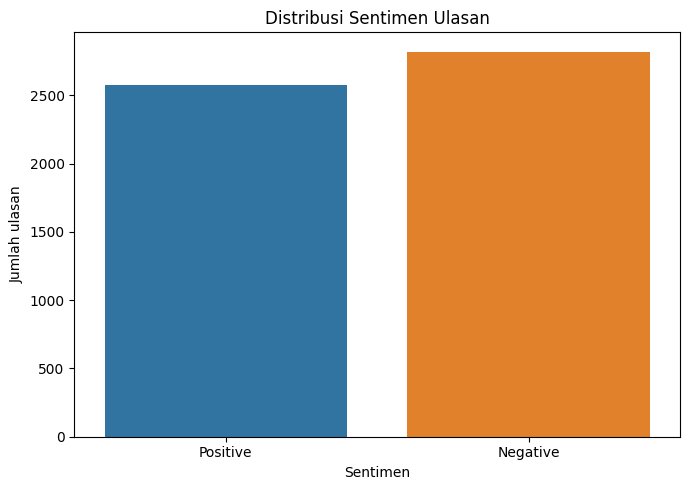

In [73]:
assert "Sentiment" in df.columns, "Kolom Sentiment tidak ditemukan."

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="Sentiment",
    hue="Sentiment",
    legend=False
)
plt.title("Distribusi Sentimen Ulasan")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah ulasan")
plt.tight_layout()
plt.show()

## Distribusi panjang teks

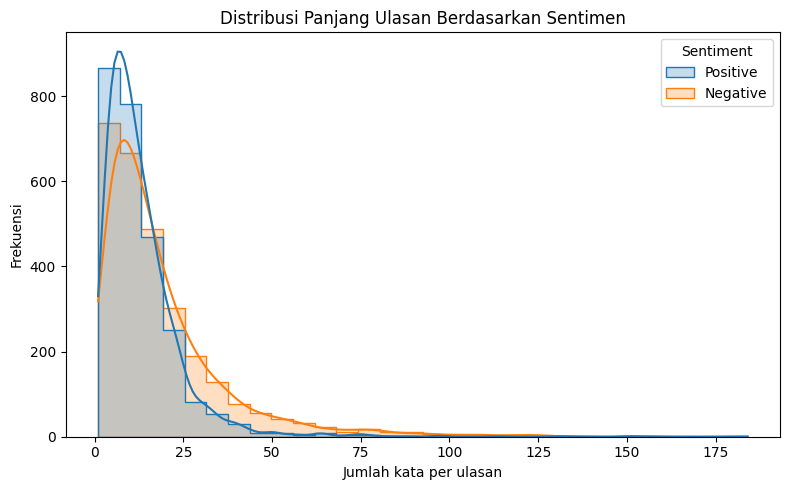

In [74]:
df["word_count"] = (
    df["Customer Review"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="word_count",
    hue="Sentiment",
    bins=30,
    kde=True,
    element="step"
)
plt.title("Distribusi Panjang Ulasan Berdasarkan Sentimen")
plt.xlabel("Jumlah kata per ulasan")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

## Heatmap korelasi atribut numerik

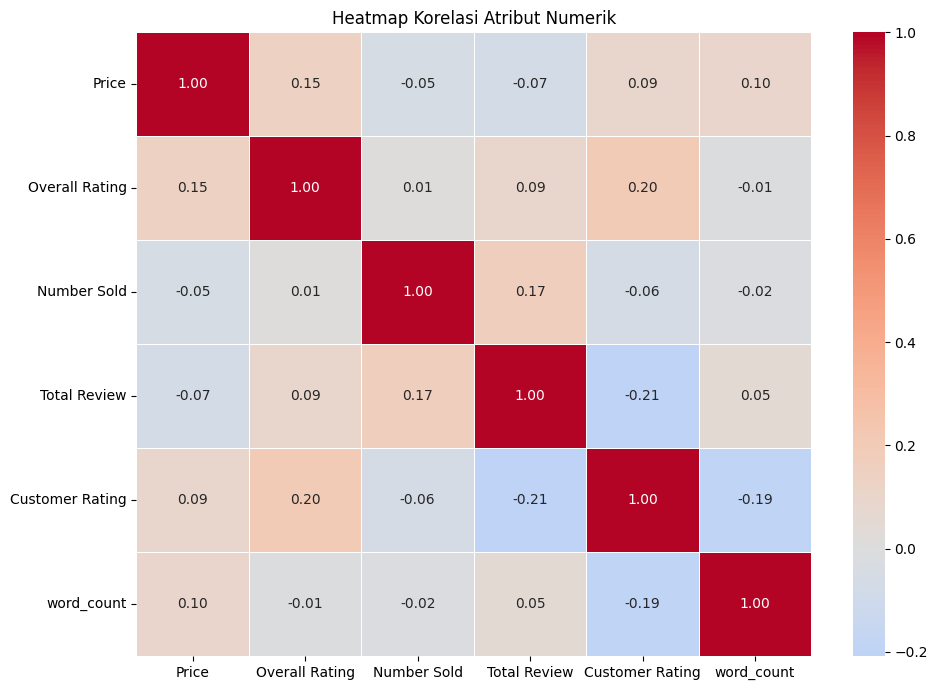

In [75]:
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    correlation = numeric_df.corr()

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        correlation,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5
    )
    plt.title("Heatmap Korelasi Atribut Numerik")
    plt.tight_layout()
    plt.show()
else:
    print("Atribut numerik tidak cukup untuk heatmap korelasi.")

## 4. Data preprocessing

Label dinormalisasi menjadi `Negative` dan `Positive`. Notebook memeriksa label yang benar-benar ada di dataset sebelum melanjutkan. Baris dengan teks kosong atau label yang tidak dikenali tidak digunakan.

In [76]:
required = {"Customer Review", "Sentiment"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(
        f"Kolom wajib tidak ditemukan: {missing_required}. "
        f"Kolom tersedia: {df.columns.tolist()}"
    )

work = df[["Customer Review", "Sentiment"]].copy()
work["Customer Review"] = work["Customer Review"].fillna("").astype(str).str.strip()
work["Sentiment"] = work["Sentiment"].astype(str).str.strip().str.lower()

label_map = {
    "positive": "Positive",
    "positif": "Positive",
    "negative": "Negative",
    "negatif": "Negative",
}
work["Sentiment"] = work["Sentiment"].map(label_map)

work = work[(work["Customer Review"] != "") & work["Sentiment"].notna()].copy()
work = work.drop_duplicates(subset=["Customer Review", "Sentiment"]).reset_index(drop=True)

print("Ukuran setelah validasi:", work.shape)
print("\nDistribusi target:")
display(work["Sentiment"].value_counts().to_frame("jumlah"))
display((work["Sentiment"].value_counts(normalize=True) * 100).round(2).to_frame("persentase"))

Ukuran setelah validasi: (5305, 2)

Distribusi target:


,jumlah
Sentiment,
Negative,2752
Positive,2553


,persentase
Sentiment,
Negative,51.88
Positive,48.12


## 5. Pembagian data train dan test

Data dibagi menjadi 80% training dan 20% testing. `stratify=y` menjaga proporsi label pada kedua subset. Test set hanya dipakai untuk evaluasi akhir.

In [77]:
X = work["Customer Review"].astype(str)
y = work["Sentiment"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Data training:", len(X_train))
print("Data testing :", len(X_test))
print("\nProporsi target pada test:")
display(y_test.value_counts(normalize=True).round(3).to_frame("proporsi"))

Data training: 4244
Data testing : 1061

Proporsi target pada test:


,proporsi
Sentiment,
Negative,0.518
Positive,0.482


## 6. Membangun dan melatih model

In [78]:
models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_features=20000,
            sublinear_tf=True
        )),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_features=20000,
            sublinear_tf=True
        )),
        ("clf", MultinomialNB())
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_features=20000,
            sublinear_tf=True
        )),
        ("clf", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Melatih {name} ...")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained_models[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1_macro", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Melatih Logistic Regression ...
Melatih Multinomial Naive Bayes ...
Melatih Linear SVM ...


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Linear SVM,0.9491,0.9511,0.9481,0.9489
1,Logistic Regression,0.9416,0.9435,0.9405,0.9413
2,Multinomial Naive Bayes,0.9387,0.9424,0.9372,0.9384


## Visualisasi perbandingan model

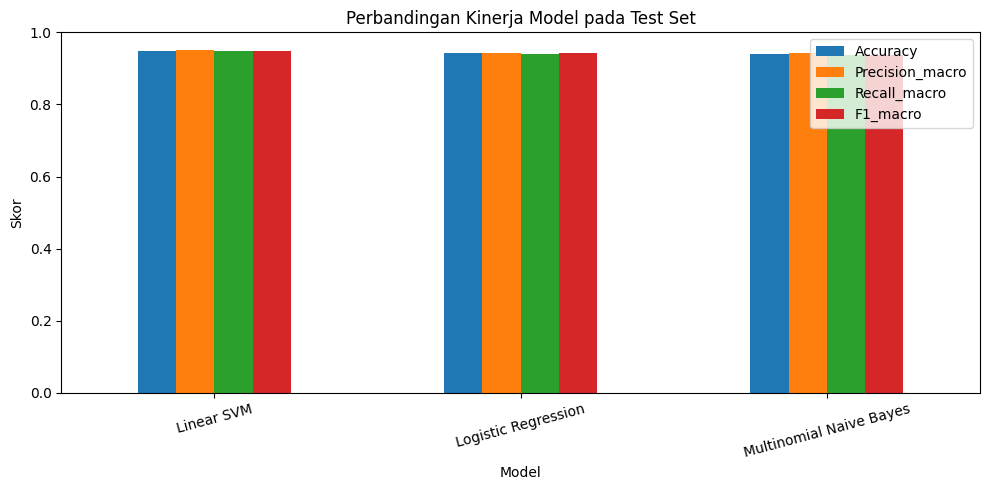

In [79]:
ax = results_df.set_index("Model")[["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]].plot(
    kind="bar", figsize=(10, 5)
)
ax.set_title("Perbandingan Kinerja Model pada Test Set")
ax.set_ylabel("Skor")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


## Classification report dan confusion matrix

Model terbaik berdasarkan macro-F1: Linear SVM

Classification Report:
              precision    recall  f1-score   support

    Negative       0.93      0.98      0.95       550
    Positive       0.97      0.92      0.95       511

    accuracy                           0.95      1061
   macro avg       0.95      0.95      0.95      1061
weighted avg       0.95      0.95      0.95      1061



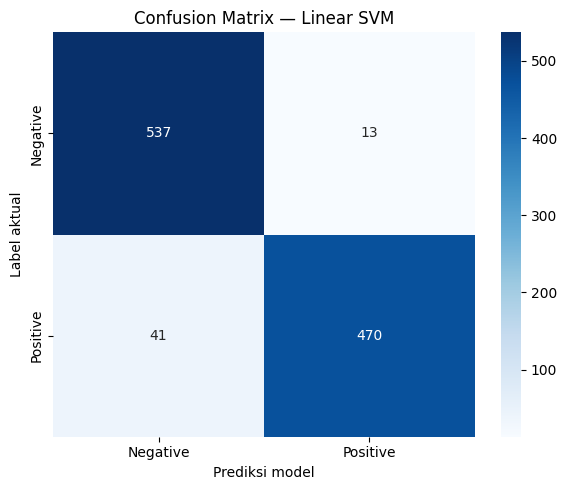

In [80]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_pred = predictions[best_model_name]

print("Model terbaik berdasarkan macro-F1:", best_model_name)
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred,
    labels=["Negative", "Positive"],
    target_names=["Negative", "Positive"],
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    best_pred,
    labels=["Negative", "Positive"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Prediksi model")
plt.ylabel("Label aktual")
plt.tight_layout()
plt.show()

## Membandingkan dengan baseline

In [81]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train.to_frame(), y_train)
baseline_pred = baseline.predict(X_test.to_frame())

baseline_scores = {
    "Model": "Majority-class baseline",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision_macro": precision_score(y_test, baseline_pred, average="macro", zero_division=0),
    "Recall_macro": recall_score(y_test, baseline_pred, average="macro", zero_division=0),
    "F1_macro": f1_score(y_test, baseline_pred, average="macro", zero_division=0)
}
display(pd.concat([results_df, pd.DataFrame([baseline_scores])], ignore_index=True).round(4))

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Linear SVM,0.9491,0.9511,0.9481,0.9489
1,Logistic Regression,0.9416,0.9435,0.9405,0.9413
2,Multinomial Naive Bayes,0.9387,0.9424,0.9372,0.9384
3,Majority-class baseline,0.5184,0.2592,0.5000,0.3414


## 7. Uji prediksi ulasan baru

Contoh ini hanya demonstrasi. Prediksi tidak selalu benar, khususnya untuk sarkasme, slang, salah ketik, dan ulasan yang memiliki sentimen campuran.

In [82]:
contoh_ulasan = [
    "Barangnya bagus, sesuai deskripsi dan pengiriman cepat.",
    "Produk rusak saat sampai, kecewa sekali dan tidak puas.",
    "Kualitasnya biasa saja, tidak terlalu bagus tetapi masih bisa dipakai."
]

prediksi_contoh = best_model.predict(contoh_ulasan)
pd.DataFrame({
    "Ulasan": contoh_ulasan,
    "Prediksi sentimen": prediksi_contoh
})

,Ulasan,Prediksi sentimen
0,"Barangnya bagus, sesuai deskripsi dan pengirim...",Positive
1,"Produk rusak saat sampai, kecewa sekali dan ti...",Negative
2,"Kualitasnya biasa saja, tidak terlalu bagus te...",Negative


## 8. Evaluasi Model

In [83]:
best_row = results_df.iloc[0]
print(f'''
RINGKASAN HASIL EKSPERIMEN
- Jumlah data yang digunakan: {len(work)}
- Jumlah data training: {len(X_train)}
- Jumlah data testing: {len(X_test)}
- Model terbaik berdasarkan macro-F1: {best_row["Model"]}
- Accuracy: {best_row["Accuracy"]:.4f}
- Macro precision: {best_row["Precision_macro"]:.4f}
- Macro recall: {best_row["Recall_macro"]:.4f}
- Macro-F1: {best_row["F1_macro"]:.4f}

Interpretasi:
Gunakan classification report dan confusion matrix untuk menjelaskan kesalahan model pada masing-masing kelas.
Jangan mengisi angka hasil laporan sebelum notebook selesai dijalankan.
''')


RINGKASAN HASIL EKSPERIMEN
- Jumlah data yang digunakan: 5305
- Jumlah data training: 4244
- Jumlah data testing: 1061
- Model terbaik berdasarkan macro-F1: Linear SVM
- Accuracy: 0.9491
- Macro precision: 0.9511
- Macro recall: 0.9481
- Macro-F1: 0.9489

Interpretasi:
Gunakan classification report dan confusion matrix untuk menjelaskan kesalahan model pada masing-masing kelas.
Jangan mengisi angka hasil laporan sebelum notebook selesai dijalankan.



## 9. Simpan Model

In [84]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

joblib.dump(best_model, output_dir / "best_sentiment_model.joblib")
results_df.to_csv(output_dir / "model_comparison.csv", index=False)

print("Model terbaik:", best_name)
print("File tersimpan di:", output_dir.resolve())
print("Isi folder:", [p.name for p in output_dir.iterdir()])

Model terbaik: Linear SVM
File tersimpan di: /content/outputs
Isi folder: ['best_sentiment_model.joblib', 'model_comparison.csv']


## Kesimpulan Studi Kasus Klasifikasi Sentimen Ulasan Produk

Berdasarkan tahapan analisis yang telah dilakukan, kesimpulan dari studi kasus klasifikasi sentimen ulasan produk menggunakan dataset PRDECT-ID adalah sebagai berikut.

1. Dataset yang digunakan

    Dataset PRDECT-ID berisi 5.400 ulasan produk berbahasa Indonesia yang berasal dari berbagai kategori produk. Pada studi kasus ini, kolom Customer Review digunakan sebagai variabel fitur atau masukan, sedangkan kolom Sentiment digunakan sebagai variabel target yang akan diprediksi.

2. Pemeriksaan dan kualitas data

    Pemeriksaan struktur dataset dilakukan untuk mengetahui jumlah observasi, tipe data, dan kelengkapan setiap kolom. Berdasarkan hasil pemeriksaan, seluruh kolom memiliki 5.400 data terisi sehingga tidak ditemukan nilai kosong yang perlu ditangani. Nilai NaN yang muncul pada statistik deskriptif gabungan tidak selalu menunjukkan data hilang, melainkan dapat terjadi karena statistik tertentu tidak berlaku untuk tipe data tertentu.

3. Tahapan preprocessing

    Data ulasan teks perlu diubah menjadi representasi numerik agar dapat diproses oleh algoritma klasifikasi. Metode TF-IDF digunakan untuk merepresentasikan tingkat kepentingan kata dalam ulasan. Tahapan ini membantu model mengenali pola kata yang berkaitan dengan sentimen positif maupun negatif.

4. Penerapan algoritma klasifikasi

    Algoritma yang digunakan untuk membandingkan kinerja klasifikasi adalah Multinomial Naive Bayes, Logistic Regression, dan Linear Support Vector Machine (Linear SVM). Perbandingan dilakukan untuk mengetahui algoritma yang paling sesuai dalam mengklasifikasikan sentimen ulasan produk.

5. Evaluasi model

    Kinerja model dievaluasi menggunakan metrik accuracy, precision, recall, dan F1-score. Confusion matrix juga digunakan untuk mengetahui jumlah prediksi yang benar maupun kesalahan klasifikasi pada setiap kelas sentimen. Hasil evaluasi tersebut menjadi dasar untuk membandingkan kemampuan masing-masing algoritma.

6. Penentuan model terbaik

    Model terbaik ditentukan berdasarkan hasil evaluasi pada data pengujian, terutama dengan memperhatikan nilai macro F1-score agar performa pada kelas positif dan negatif dapat dipertimbangkan secara seimbang. Berdasarkan hasil pengujian, model terbaik adalah [nama model terbaik], dengan accuracy sebesar [nilai accuracy]% dan macro F1-score sebesar [nilai macro F1-score].

7. Manfaat studi kasus

    Studi kasus ini menunjukkan bahwa teknik klasifikasi teks dapat digunakan untuk membantu mengidentifikasi sentimen pelanggan secara otomatis. Hasil klasifikasi berpotensi mendukung analisis ulasan produk dan membantu penjual memahami kecenderungan tanggapan pelanggan terhadap produk yang ditawarkan.
    

Secara keseluruhan, studi kasus ini mencakup proses klasifikasi mulai dari pemeriksaan data, preprocessing teks menggunakan TF-IDF, penerapan algoritma, hingga evaluasi dan perbandingan model. Hasil akhirnya diharapkan dapat menunjukkan model yang paling sesuai untuk klasifikasi sentimen ulasan produk berbahasa Indonesia berdasarkan hasil pengujian yang diperoleh.